# Do produto escalar às equações normais

Este caderno é um pequeno passeio pela álgebra linear que sustenta um dos modelos mais usados em estatística: a **regressão linear por mínimos quadrados**. Partimos de vetores e de seus produtos, mostramos como o produto matriz–vetor organiza combinações lineares e, a partir daí, deduzimos as equações normais que fornecem os coeficientes do ajuste.

O roteiro é o seguinte:

1. Vetores em $\mathbb{R}^n$, produto escalar e produto vetorial.
2. O produto matriz–vetor como combinação linear de colunas.
3. O modelo linear, a função de perda e as equações normais.
4. Um ajuste numérico em dados sintéticos, com visualização e análise de resíduos.

Todo o código usa apenas `numpy` e `matplotlib`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"

import matplotlib
import numpy as np
import matplotlib.pyplot as plt

# impressão compacta de arrays
np.set_printoptions(precision=4, suppress=True)

print(f"numpy {np.__version__} · matplotlib {matplotlib.__version__}")

numpy 2.5.4 · matplotlib 3.11.2


## Vetores e produtos

Um vetor em $\mathbb{R}^n$ é uma lista ordenada de $n$ números reais,

$$\mathbf{u} = (u_1, u_2, \dots, u_n), \qquad u_i \in \mathbb{R}.$$

O **produto escalar** associa a dois vetores um único número:

$$\mathbf{u}\cdot\mathbf{v} = \sum_{i=1}^{n} u_i v_i = \lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert\cos\theta,$$

em que $\lVert\mathbf{u}\rVert = \sqrt{\mathbf{u}\cdot\mathbf{u}}$ é a norma euclidiana e $\theta$ é o ângulo entre os vetores. Geometricamente, o produto escalar mede o quanto um vetor *aponta na direção* do outro: é positivo quando o ângulo é agudo, nulo quando os vetores são ortogonais e negativo quando o ângulo é obtuso. Isolando o cosseno, obtemos o ângulo:

$$\theta = \arccos\!\left(\frac{\mathbf{u}\cdot\mathbf{v}}{\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert}\right).$$

In [2]:
u = np.array([3.0, 1.0, 2.0])
v = np.array([1.0, 4.0, -1.0])

# produto escalar: soma dos produtos componente a componente
dot = u @ v
norm_u, norm_v = np.linalg.norm(u), np.linalg.norm(v)

# ângulo entre os vetores, em radianos e em graus
theta = np.arccos(dot / (norm_u * norm_v))

print(f"u · v      = {dot:.4f}")
print(f"‖u‖, ‖v‖   = {norm_u:.4f}, {norm_v:.4f}")
print(f"θ          = {theta:.4f} rad  ({np.degrees(theta):.2f}°)")

u · v      = 5.0000
‖u‖, ‖v‖   = 3.7417, 4.2426
θ          = 1.2504 rad  (71.64°)


### Produto vetorial

Em $\mathbb{R}^3$ existe ainda o **produto vetorial**, que devolve um vetor. Ele pode ser escrito como um determinante formal, com os vetores canônicos $\mathbf{i}, \mathbf{j}, \mathbf{k}$ na primeira linha:

$$
\mathbf{u}\times\mathbf{v} =
\begin{vmatrix}
\mathbf{i} & \mathbf{j} & \mathbf{k} \\
u_1 & u_2 & u_3 \\
v_1 & v_2 & v_3
\end{vmatrix}
= (u_2 v_3 - u_3 v_2)\,\mathbf{i} - (u_1 v_3 - u_3 v_1)\,\mathbf{j} + (u_1 v_2 - u_2 v_1)\,\mathbf{k}.
$$

O resultado é **ortogonal a ambos** os fatores, e sua norma vale $\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert\sin\theta$, a área do paralelogramo gerado por $\mathbf{u}$ e $\mathbf{v}$. Podemos verificar a ortogonalidade numericamente: os produtos escalares $(\mathbf{u}\times\mathbf{v})\cdot\mathbf{u}$ e $(\mathbf{u}\times\mathbf{v})\cdot\mathbf{v}$ devem ser nulos, a menos de erro de arredondamento.

In [3]:
w = np.cross(u, v)

print(f"u × v         = {w}")
print(f"(u × v) · u   = {w @ u:+.2e}")
print(f"(u × v) · v   = {w @ v:+.2e}")

# a norma do produto vetorial é a área do paralelogramo
area = norm_u * norm_v * np.sin(theta)
print(f"‖u × v‖       = {np.linalg.norm(w):.4f}   (‖u‖‖v‖ sen θ = {area:.4f})")

u × v         = [-9.  5. 11.]
(u × v) · u   = +0.00e+00
(u × v) · v   = +0.00e+00
‖u × v‖       = 15.0665   (‖u‖‖v‖ sen θ = 15.0665)


### Produto matriz–vetor

Seja $A \in \mathbb{R}^{m\times n}$ com colunas $\mathbf{a}_1, \dots, \mathbf{a}_n$. O produto $A\mathbf{x}$ costuma ser apresentado linha a linha, como uma sequência de produtos escalares; mas a leitura mais útil é **por colunas**:

$$
A\mathbf{x} =
\begin{pmatrix}
\vert & & \vert \\
\mathbf{a}_1 & \cdots & \mathbf{a}_n \\
\vert & & \vert
\end{pmatrix}
\begin{pmatrix} x_1 \\ \vdots \\ x_n \end{pmatrix}
= \sum_{j=1}^{n} x_j \mathbf{a}_j .
$$

Ou seja, $A\mathbf{x}$ é uma **combinação linear das colunas** de $A$, com pesos dados pelas entradas de $\mathbf{x}$. Essa ideia é exatamente a que usaremos na regressão: os valores ajustados serão uma combinação das colunas da matriz de dados.

In [4]:
A = np.array([[2.0, -1.0],
              [0.0,  3.0],
              [1.0,  1.0]])
x = np.array([2.0, 0.5])

# duas leituras do mesmo produto
por_linhas = A @ x
por_colunas = x[0] * A[:, 0] + x[1] * A[:, 1]

print("A x (por linhas)  =", por_linhas)
print("Σ x_j a_j         =", por_colunas)
print("iguais?           =", np.allclose(por_linhas, por_colunas))

A x (por linhas)  = [3.5 1.5 2.5]
Σ x_j a_j         = [3.5 1.5 2.5]
iguais?           = True


## Regressão linear: do modelo às equações normais

Dispomos de $n$ pares $(x_i, y_i)$ e supomos que a resposta depende linearmente da variável explicativa, a menos de um ruído aleatório:

$$y_i = \beta_0 + \beta_1 x_i + \varepsilon_i, \qquad i = 1, \dots, n.$$

Empilhando as $n$ equações, o modelo ganha uma forma matricial compacta, $\mathbf{y} = X\boldsymbol\beta + \boldsymbol\varepsilon$, com

$$
\underbrace{\begin{pmatrix} y_1 \\ y_2 \\ \vdots \\ y_n \end{pmatrix}}_{\mathbf{y}}
=
\underbrace{\begin{pmatrix} 1 & x_1 \\ 1 & x_2 \\ \vdots & \vdots \\ 1 & x_n \end{pmatrix}}_{X}
\underbrace{\begin{pmatrix} \beta_0 \\ \beta_1 \end{pmatrix}}_{\boldsymbol\beta}
+
\underbrace{\begin{pmatrix} \varepsilon_1 \\ \varepsilon_2 \\ \vdots \\ \varepsilon_n \end{pmatrix}}_{\boldsymbol\varepsilon}.
$$

A coluna de uns carrega o intercepto $\beta_0$. Pela leitura por colunas, $X\boldsymbol\beta = \beta_0 \mathbf{1} + \beta_1 \mathbf{x}$: o ajuste é uma combinação linear das duas colunas de $X$.

### Função de perda e equações normais

O critério de mínimos quadrados escolhe $\boldsymbol\beta$ que minimiza a soma dos quadrados dos resíduos:

$$S(\boldsymbol\beta) = \lVert \mathbf{y} - X\boldsymbol\beta \rVert^2 .$$

Expandindo o quadrado da norma como um produto escalar:

$$
\begin{aligned}
S(\boldsymbol\beta)
&= (\mathbf{y} - X\boldsymbol\beta)^\top (\mathbf{y} - X\boldsymbol\beta) \\
&= \mathbf{y}^\top\mathbf{y} - \mathbf{y}^\top X\boldsymbol\beta - \boldsymbol\beta^\top X^\top\mathbf{y} + \boldsymbol\beta^\top X^\top X\boldsymbol\beta \\
&= \mathbf{y}^\top\mathbf{y} - 2\,\boldsymbol\beta^\top X^\top\mathbf{y} + \boldsymbol\beta^\top X^\top X\boldsymbol\beta ,
\end{aligned}
$$

onde usamos que $\mathbf{y}^\top X\boldsymbol\beta$ é um escalar e, portanto, igual ao seu transposto. Derivando em relação a $\boldsymbol\beta$ e igualando a zero:

$$\nabla S(\boldsymbol\beta) = -2\,X^\top\mathbf{y} + 2\,X^\top X\boldsymbol\beta = \mathbf{0}.$$

Chegamos às **equações normais**

$$X^\top X\,\hat{\boldsymbol\beta} = X^\top \mathbf{y},$$

que, quando $X^\top X$ é invertível (colunas de $X$ linearmente independentes), têm solução única

$$\hat{\boldsymbol\beta} = (X^\top X)^{-1}X^\top\mathbf{y}.$$

> **Observação.** A fórmula com a inversa é ótima no papel, mas ruim no computador. Formar $(X^\top X)^{-1}$ explicitamente custa mais e amplifica erros de arredondamento. Na prática resolvemos o sistema linear diretamente com `np.linalg.solve`, ou, melhor ainda, usamos `np.linalg.lstsq`, que trabalha sobre $X$ via decomposição SVD e nem sequer forma $X^\top X$.

### O caso simples em forma fechada

Com uma única variável explicativa, as equações normais podem ser resolvidas à mão. As derivadas parciais de $S(\beta_0, \beta_1) = \sum_i (y_i - \beta_0 - \beta_1 x_i)^2$ são

$$
\frac{\partial S}{\partial \beta_0} = -2\sum_{i=1}^{n} (y_i - \beta_0 - \beta_1 x_i) = 0,
\qquad
\frac{\partial S}{\partial \beta_1} = -2\sum_{i=1}^{n} x_i\,(y_i - \beta_0 - \beta_1 x_i) = 0 .
$$

A primeira equação dá $\beta_0 = \bar y - \beta_1 \bar x$; substituindo na segunda e reorganizando em torno das médias $\bar x$ e $\bar y$, obtemos

$$\hat\beta_1 = \frac{\sum_{i=1}^{n} (x_i-\bar x)(y_i-\bar y)}{\sum_{i=1}^{n} (x_i-\bar x)^2},\qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x .$$

O numerador é (a menos de um fator $n-1$) a covariância amostral entre $x$ e $y$; o denominador, a variância de $x$. Vamos gerar dados sintéticos em torno da reta $y = 1 + 2{,}5\,x$ e conferir que os três caminhos levam ao mesmo lugar.

In [5]:
rng = np.random.default_rng(42)

n = 60
beta_verdadeiro = np.array([1.0, 2.5])   # (β0, β1)

x = np.sort(rng.uniform(0, 10, size=n))
y = beta_verdadeiro[0] + beta_verdadeiro[1] * x + rng.normal(0, 2.0, size=n)

# matriz de planejamento: coluna de uns + coluna de x
X = np.column_stack([np.ones(n), x])

print(f"X tem formato {X.shape}; primeiras linhas:")
print(X[:4])

X tem formato (60, 2); primeiras linhas:
[[1.     0.0736]
 [1.     0.438 ]
 [1.     0.6382]
 [1.     0.9418]]


In [6]:
# 1) equações normais, resolvidas como sistema linear
beta_normal = np.linalg.solve(X.T @ X, X.T @ y)

# 2) forma fechada do caso simples
x_bar, y_bar = x.mean(), y.mean()
b1 = np.sum((x - x_bar) * (y - y_bar)) / np.sum((x - x_bar) ** 2)
b0 = y_bar - b1 * x_bar
beta_fechada = np.array([b0, b1])

# 3) mínimos quadrados via SVD
beta_lstsq, *_ = np.linalg.lstsq(X, y, rcond=None)

print(f"{'método':<22}{'β0':>10}{'β1':>10}")
print("-" * 42)
for nome, b in [("equações normais", beta_normal),
                ("forma fechada", beta_fechada),
                ("np.linalg.lstsq", beta_lstsq)]:
    print(f"{nome:<22}{b[0]:>10.4f}{b[1]:>10.4f}")

print("\nconcordam?", np.allclose(beta_normal, beta_fechada) and np.allclose(beta_normal, beta_lstsq))

método                        β0        β1
------------------------------------------
equações normais          0.8684    2.4456
forma fechada             0.8684    2.4456
np.linalg.lstsq           0.8684    2.4456

concordam? True


Os três métodos concordam até a última casa exibida, e os valores estimados ficam próximos dos parâmetros verdadeiros $(1{,}0;\ 2{,}5)$ usados na simulação:

| Método | Fórmula | $\hat\beta_0$ | $\hat\beta_1$ |
|:--|:--|--:|--:|
| Equações normais | `solve(X.T @ X, X.T @ y)` | 0,8684 | 2,4456 |
| Forma fechada | $\hat\beta_1 = S_{xy}/S_{xx}$ | 0,8684 | 2,4456 |
| Mínimos quadrados (SVD) | `lstsq(X, y)` | 0,8684 | 2,4456 |

Para medir a qualidade do ajuste, usamos o **coeficiente de determinação**, a fração da variabilidade de $y$ explicada pelo modelo,

$$R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i-\hat y_i)^2}{\sum_{i=1}^{n} (y_i-\bar y)^2},$$

e a raiz do erro quadrático médio, $\mathrm{RMSE} = \sqrt{\tfrac{1}{n}\sum_i (y_i - \hat y_i)^2}$, que está na mesma unidade de $y$.

In [7]:
beta_hat = beta_normal
y_hat = X @ beta_hat
residuos = y - y_hat

sq_res = np.sum(residuos ** 2)
sq_tot = np.sum((y - y_bar) ** 2)
r2 = 1 - sq_res / sq_tot
rmse = np.sqrt(sq_res / n)
s = np.sqrt(sq_res / (n - 2))   # desvio-padrão residual (n - 2 graus de liberdade)

print("Resumo do ajuste")
print("=" * 34)
print(f"  observações       n = {n:>8d}")
print(f"  intercepto       β0 = {beta_hat[0]:>8.4f}")
print(f"  inclinação       β1 = {beta_hat[1]:>8.4f}")
print(f"  R²                  = {r2:>8.4f}")
print(f"  RMSE                = {rmse:>8.4f}")
print(f"  desvio residual   s = {s:>8.4f}")

Resumo do ajuste
  observações       n =       60
  intercepto       β0 =   0.8684
  inclinação       β1 =   2.4456
  R²                  =   0.9553
  RMSE                =   1.4881
  desvio residual   s =   1.5135


## Visualizando o ajuste

O gráfico abaixo mostra os dados, a reta ajustada $\hat y = \hat\beta_0 + \hat\beta_1 x$ e uma faixa de $\pm s$ em torno dela, onde $s$ é o desvio-padrão residual. O estilo é aplicado apenas a esta figura, por meio de `plt.rc_context`, para não alterar as configurações globais do `matplotlib`.

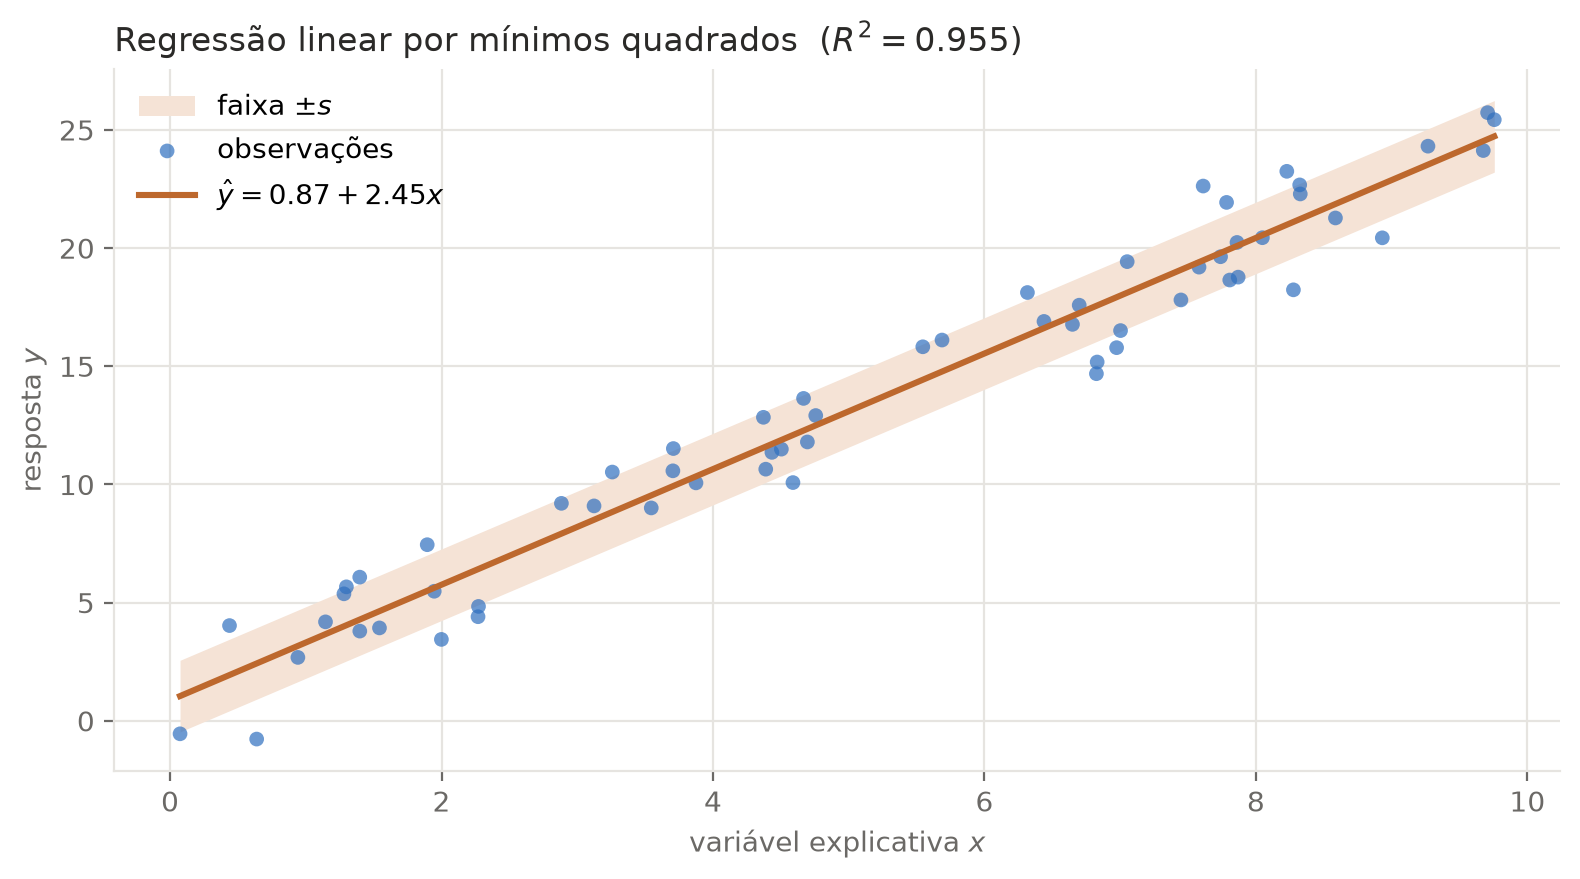

In [8]:
# paleta alinhada ao tema
AZUL, LARANJA, LARANJA_CLARO = "#2f6fbf", "#bd682d", "#f5e3d6"
GRADE, TEXTO = "#e6e4e0", "#6b6966"

estilo = {
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRADE,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "axes.labelcolor": TEXTO,
    "xtick.color": TEXTO,
    "ytick.color": TEXTO,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.titlecolor": "#2b2a28",
    "legend.frameon": False,
}

with plt.rc_context(estilo):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.set_axisbelow(True)

    xs = np.linspace(x.min(), x.max(), 200)
    ys = beta_hat[0] + beta_hat[1] * xs

    ax.fill_between(xs, ys - s, ys + s, color=LARANJA_CLARO, linewidth=0,
                    label=r"faixa $\pm s$")
    ax.scatter(x, y, s=28, color=AZUL, alpha=0.7, edgecolor="none",
               label="observações")
    ax.plot(xs, ys, color=LARANJA, linewidth=2.2,
            label=rf"$\hat y = {beta_hat[0]:.2f} + {beta_hat[1]:.2f}x$")

    ax.set_title(rf"Regressão linear por mínimos quadrados  ($R^2 = {r2:.3f}$)")
    ax.set_xlabel("variável explicativa $x$")
    ax.set_ylabel("resposta $y$")
    ax.legend(loc="upper left")

    fig.tight_layout()
    plt.show()

### Resíduos

Se o modelo linear é adequado, os resíduos $e_i = y_i - \hat y_i$ devem se espalhar em torno de zero, sem tendência aparente em função de $x$. Uma consequência direta das equações normais é que $X^\top \mathbf{e} = \mathbf{0}$: o vetor de resíduos é **ortogonal** às colunas de $X$, em particular à coluna de uns, de modo que os resíduos somam zero.

Xᵀe                = (-4.4e-14, -4.9e-13)
média dos resíduos = -7.18e-16
mín / máx          = -3.199 / 3.144


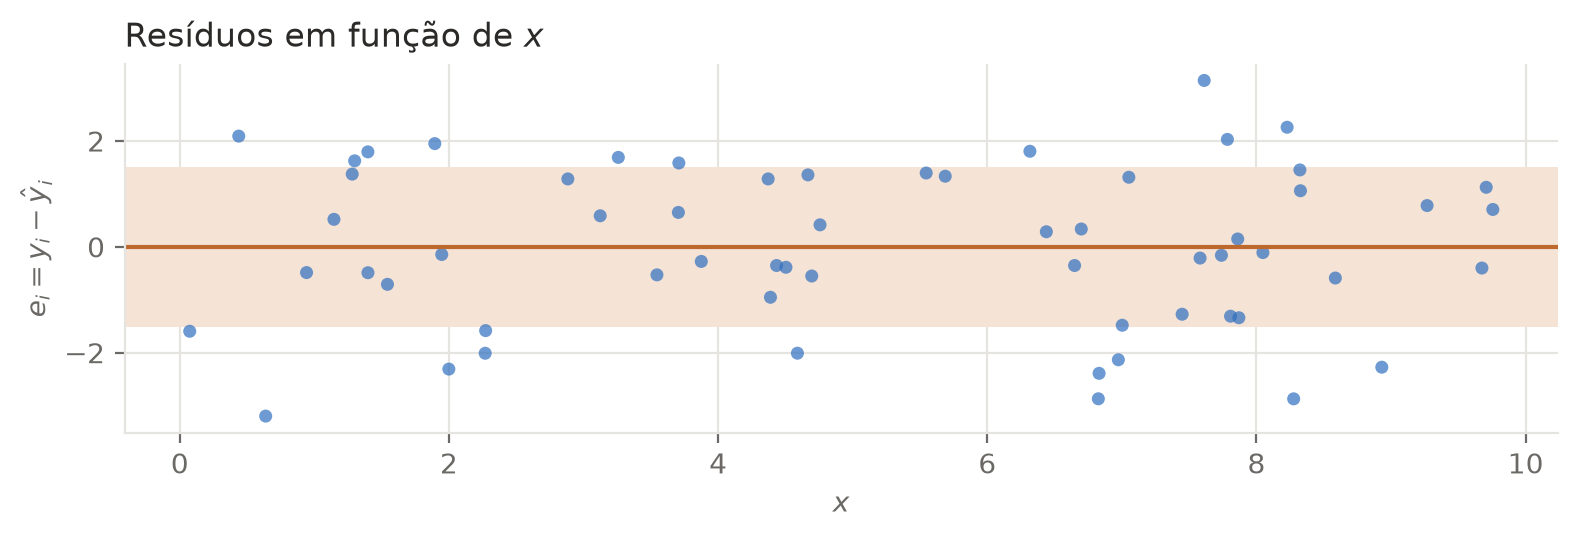

In [9]:
# ortogonalidade dos resíduos às colunas de X
Xt_e = X.T @ residuos
print(f"Xᵀe                = ({Xt_e[0]:+.1e}, {Xt_e[1]:+.1e})")
print(f"média dos resíduos = {residuos.mean():+.2e}")
print(f"mín / máx          = {residuos.min():.3f} / {residuos.max():.3f}")

with plt.rc_context(estilo):
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.set_axisbelow(True)
    ax.axhline(0, color=LARANJA, linewidth=1.5)
    ax.axhspan(-s, s, color=LARANJA_CLARO, linewidth=0)
    ax.scatter(x, residuos, s=22, color=AZUL, alpha=0.7, edgecolor="none")
    ax.set_title("Resíduos em função de $x$")
    ax.set_xlabel("$x$")
    ax.set_ylabel(r"$e_i = y_i - \hat y_i$")
    fig.tight_layout()
    plt.show()

## Resumo

- O produto escalar mede alinhamento entre vetores; o produto vetorial, em $\mathbb{R}^3$, produz um vetor ortogonal a ambos.
- O produto $A\mathbf{x}$ é uma combinação linear das colunas de $A$, e os valores ajustados $X\hat{\boldsymbol\beta}$ são exatamente isso.
- Minimizar $\lVert \mathbf{y} - X\boldsymbol\beta \rVert^2$ leva às equações normais, que devem ser resolvidas como sistema linear (`solve`) ou por métodos ortogonais (`lstsq`), nunca por inversão explícita.
- No exemplo, os três métodos coincidem e recuperam bem os parâmetros verdadeiros, com $R^2$ próximo de $0{,}96$.

Tudo se resume a uma afirmação geométrica: o resíduo ótimo é perpendicular ao espaço gerado pelas colunas de $X$,

$$X^\top\big(\mathbf{y} - X\hat{\boldsymbol\beta}\big) = \mathbf{0} \quad\Longleftrightarrow\quad X\hat{\boldsymbol\beta} = \operatorname{proj}_{\,\mathcal{C}(X)}\,\mathbf{y}.$$